1225 images


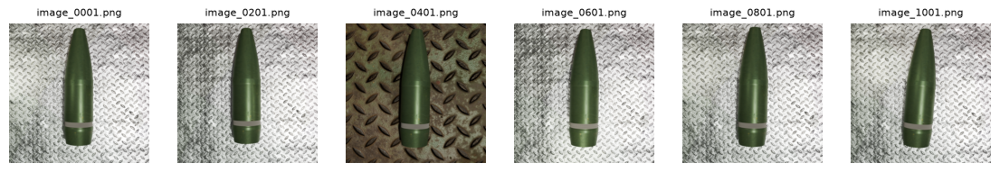

In [1]:
import os
from pathlib import Path
os.environ.setdefault("TORCH_HOME", str(Path("weights").resolve()))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

IMG_DIR = Path("data/images")
files = sorted(p for p in IMG_DIR.glob("*.png") if "(" not in p.name)
print(len(files), "images")

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, p in zip(axes, files[::200]):
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(p.name, fontsize=8); ax.axis("off")
plt.show()

In [2]:
dev = "cuda"
torch.manual_seed(0)

net = torchvision.models.wide_resnet50_2(weights="IMAGENET1K_V1").to(dev).eval()
feats = {}
net.layer2.register_forward_hook(lambda m, i, o: feats.__setitem__("l2", o))
net.layer3.register_forward_hook(lambda m, i, o: feats.__setitem__("l3", o))

mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
proj = torch.randn(512 + 1024, 256, device=dev) / 256 ** 0.5   


@torch.no_grad()
def embed(batch):
    net((batch - mean) / std)
    l2 = F.avg_pool2d(feats["l2"], 3, 1, 1)
    l3 = F.interpolate(F.avg_pool2d(feats["l3"], 3, 1, 1), size=l2.shape[-2:], mode="bilinear", align_corners=False)
    f = torch.cat([l2, l3], 1)
    B, C, H, W = f.shape
    return (f.permute(0, 2, 3, 1).reshape(B, H * W, C) @ proj).half(), (H, W)


test = torch.from_numpy(np.asarray(Image.open(files[0]).convert("RGB"), dtype=np.float32) / 255).permute(2, 0, 1)[None].to(dev)
f, hw = embed(test)
print("patch grid:", hw, "| features per image:", tuple(f.shape))

patch grid: (64, 64) | features per image: (1, 4096, 256)


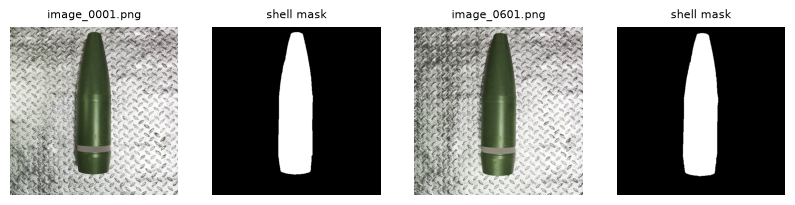

In [6]:
from scipy import ndimage


def shell_mask(rgb):
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    green = (g > r * 1.08) & (g > b * 1.08) & (g > 0.12)
    green = ndimage.binary_opening(green, iterations=2)
    lab, n = ndimage.label(green)
    if n == 0:
        return green
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    shell = np.isin(lab, np.flatnonzero(sizes >= 0.2 * sizes.max()))
    mask = np.zeros_like(shell)
    for y in range(shell.shape[0]):
        xs = np.flatnonzero(shell[y])
        if len(xs):
            mask[y, xs[0]:xs[-1] + 1] = True
    mask = ndimage.binary_closing(mask, structure=np.ones((25, 1)))
    return ndimage.binary_fill_holes(mask)


fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for k, p in enumerate([files[0], files[600]]):
    rgb = np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) / 255
    axes[2 * k].imshow(rgb); axes[2 * k].set_title(p.name, fontsize=8)
    axes[2 * k + 1].imshow(shell_mask(rgb), cmap="gray"); axes[2 * k + 1].set_title("shell mask", fontsize=8)
for a in axes:
    a.axis("off")
plt.show()

In [7]:
patches, glob_vecs, shell_grid = [], [], []
for i in range(0, len(files), 8):
    ims = [np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) / 255 for p in files[i:i + 8]]
    batch = torch.from_numpy(np.stack(ims)).permute(0, 3, 1, 2).to(dev)
    f, hw = embed(batch)
    patches.append(f)
    glob_vecs.append(F.normalize(f.float().mean(1), dim=1))
    for rgb in ims:
        m = torch.from_numpy(shell_mask(rgb)).float()[None, None]
        m = F.max_pool2d(F.interpolate(m, size=hw, mode="area"), 3, 1, 1)[0, 0] > 0.05
        shell_grid.append(m)

P = torch.cat(patches)                  
G = torch.cat(glob_vecs)                 
S = torch.stack(shell_grid).to(dev)      
print("patch features:", tuple(P.shape), "| GPU memory used: %.1f GB" % (torch.cuda.memory_allocated() / 1e9))

patch features: (1225, 4096, 256) | GPU memory used: 5.5 GB


In [8]:
del patches                       
torch.cuda.empty_cache()

K = 40
sim = G @ G.T                     
sim.fill_diagonal_(-1)           
neighbours = sim.topk(K, dim=1).indices

N, HW, D = P.shape
scores = np.zeros(N)
maps = np.zeros((N, *hw), dtype=np.float32)
for n in range(N):
    q = P[n].float()                                    
    bank = P[neighbours[n]].reshape(-1, D)              
    best = torch.full((HW,), float("inf"), device=dev)
    for chunk in bank.split(40960):                   
        best = torch.minimum(best, torch.cdist(q, chunk.float()).min(1).values)
    m = F.avg_pool2d(best.view(1, 1, *hw), 3, 1, 1)[0, 0]   
    maps[n] = m.cpu().numpy()
    scores[n] = m[S[n]].max().item() if S[n].any() else m.max().item()
    if n % 200 == 0:
        print(f"{n} / {N}")

ranking = pd.DataFrame({"image": [p.name for p in files], "score": scores}).sort_values("score", ascending=False)
ranking["rank"] = range(1, N + 1)
ranking.head(30)

0 / 1225
200 / 1225
400 / 1225
600 / 1225
800 / 1225
1000 / 1225
1200 / 1225


,image,score,rank
842,image_0843.png,2.700070,1
465,image_0466.png,2.682951,2
1194,image_1195.png,2.631605,3
1169,image_1170.png,2.604119,4
401,image_0402.png,2.517956,5
934,image_0935.png,2.502750,6
268,image_0269.png,2.267421,7
1070,image_1071.png,2.234479,8
247,image_0248.png,2.228271,9
831,image_0832.png,2.218364,10


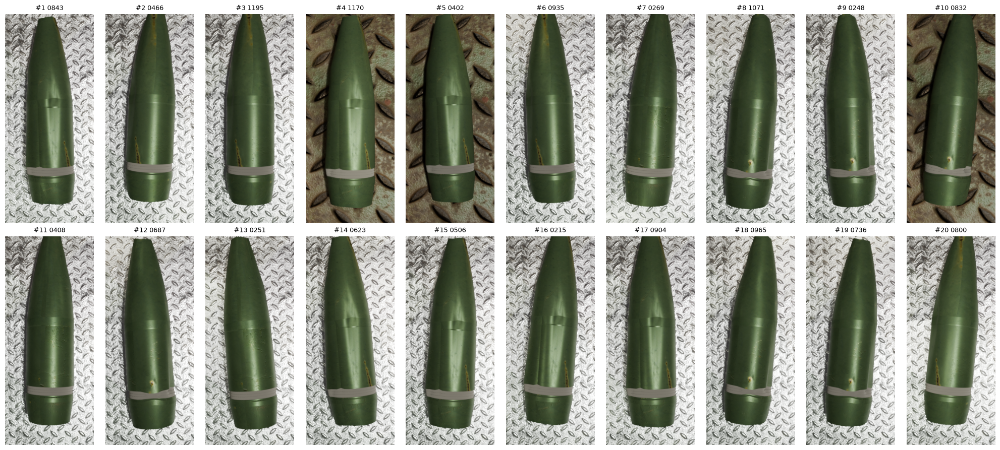

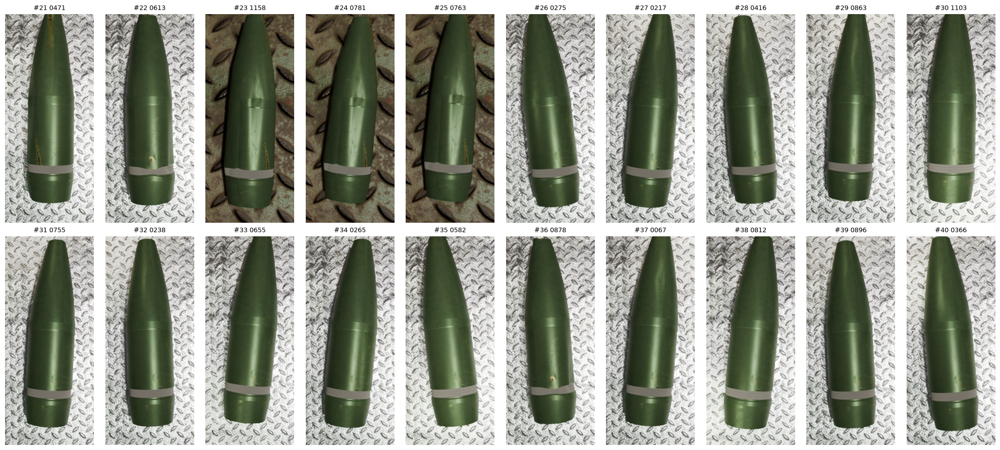

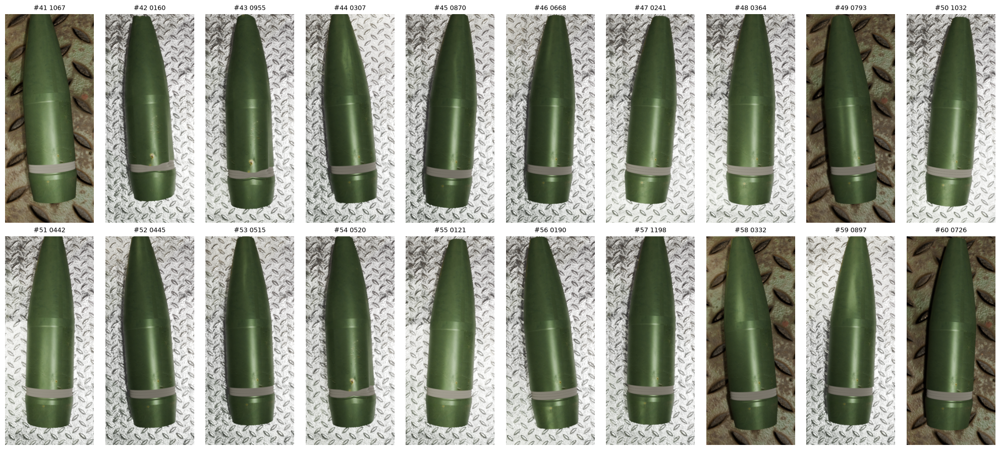

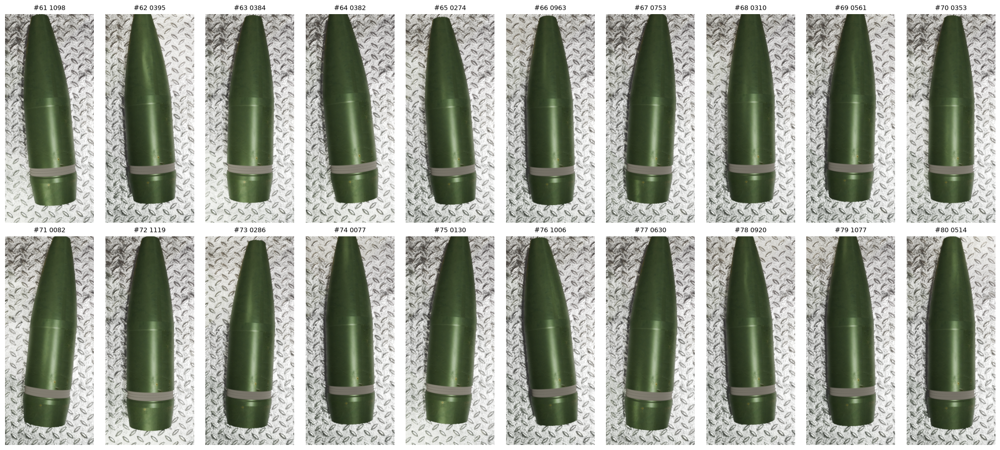

              image     score  rank
877  image_0878.png  1.260963    36
159  image_0160.png  1.225480    42
954  image_0955.png  1.220001    43
519  image_0520.png  1.202395    54


In [9]:
ranking.to_csv("ranking.csv", index=False)


def review_sheet(start, end):
    rows = ranking.iloc[start:end]
    fig, axes = plt.subplots(2, 10, figsize=(20, 9))
    for ax, r in zip(axes.flat, rows.itertuples()):
        rgb = np.asarray(Image.open(IMG_DIR / r.image).convert("RGB"))
        cols = np.flatnonzero(shell_mask(rgb / 255.0).any(0))
        cx = int(cols.mean()) if len(cols) else 256
        ax.imshow(rgb[20:490, max(cx - 100, 0):cx + 100])
        ax.set_title(f"#{r.rank} {r.image[6:10]}", fontsize=9)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


for start in range(0, 80, 20):
    review_sheet(start, start + 20)

print(ranking[ranking.image.str[6:10].isin(["0878", "0160", "0955", "0520"])])

29 confirmed, 28 submitted, left out: ['image_0520.png']
['images/image_0843.png', 'images/image_0466.png', 'images/image_1195.png'] ...


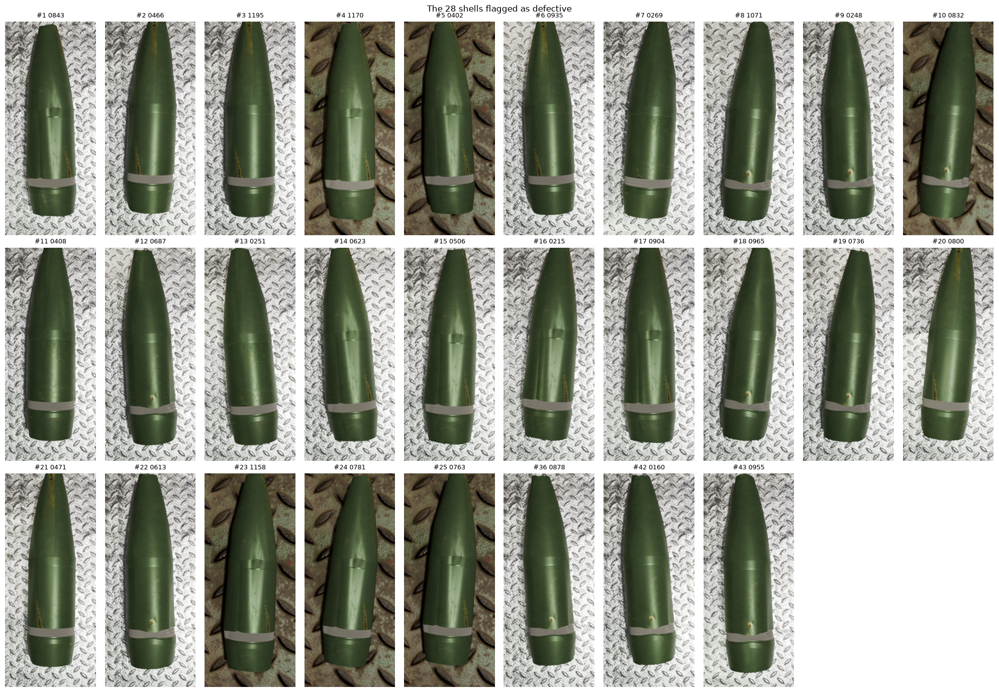

In [10]:
holes_found_in_review = ["image_0878.png", "image_0160.png", "image_0955.png", "image_0520.png"]
confirmed = ranking[(ranking["rank"] <= 25) | ranking.image.isin(holes_found_in_review)]
final = confirmed.head(28)                        

with open("test-output.txt", "w", newline="\n") as fh:
    fh.write("\n".join("images/" + name for name in final.image))

print(len(confirmed), "confirmed,", len(final), "submitted, left out:", confirmed.image.iloc[28:].tolist())
print(open("test-output.txt").read().splitlines()[:3], "...")

fig, axes = plt.subplots(3, 10, figsize=(20, 14))
for ax, r in zip(axes.flat, final.itertuples()):
    rgb = np.asarray(Image.open(IMG_DIR / r.image).convert("RGB"))
    cols = np.flatnonzero(shell_mask(rgb / 255.0).any(0))
    cx = int(cols.mean()) if len(cols) else 256
    ax.imshow(rgb[20:490, max(cx - 100, 0):cx + 100]); ax.set_title(f"#{r.rank} {r.image[6:10]}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("The 28 shells flagged as defective")
plt.tight_layout()
plt.savefig("figures/final_28.png", dpi=80)
plt.show()